# Модуль 2. Вероятностные распределения

Решения заданий для самопроверки и пять графиков из урока о программных инструментах. Для повторного запуска выполни все ячейки по порядку.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 125})

## Урок 2. Терминология

- **2.1. Утверждения 2 и 3.** Пространство исходов равно `{1, …, 10}`. Каждая карточка имеет вероятность 0.1. Значения больше семи образуют множество `{8, 9, 10}`.
- **2.2. Утверждения 2 и 4.** Орёл и решка дополняют друг друга. Для честной монеты обе вероятности равны 0.5.
- **2.3. Вариант 1.** По соглашению SciPy функция распределения Бернулли равна 0 при x < 0, 0.4 при 0 ≤ x < 1 и 1 при x ≥ 1.
- **2.4. Ответ `3.9,4.1`.** Вторая величина получена округлением дисперсии 4.09.

In [2]:
values = np.array([2, 5, 7])
probabilities = np.array([0.5, 0.3, 0.2])
expectation = np.dot(values, probabilities)
variance = np.dot((values - expectation) ** 2, probabilities)
print(f"{expectation:.1f},{variance:.1f}")

3.9,4.1


## 3.1. Плотность стандартного нормального распределения

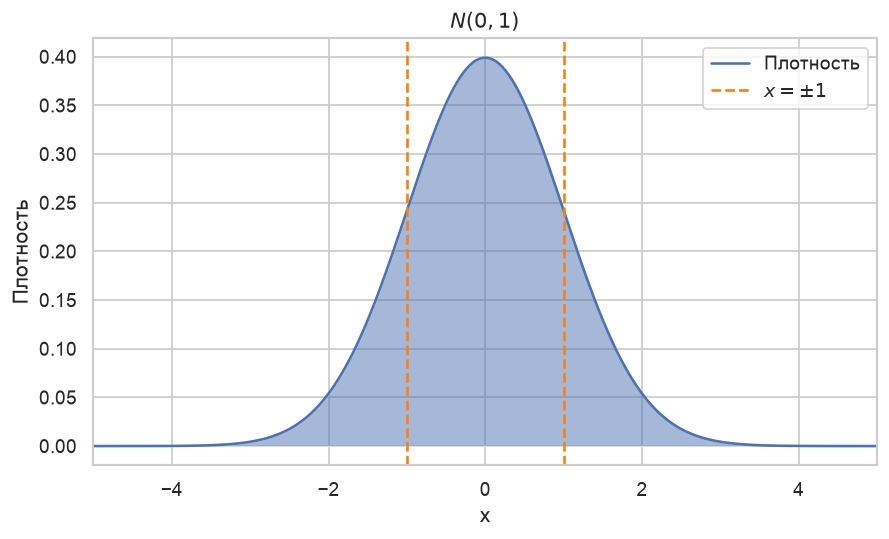

In [3]:
x = np.linspace(-5, 5, 501)
density = stats.norm.pdf(x)

fig, ax = plt.subplots(figsize=(7, 4.2), layout="constrained")
ax.plot(x, density, label="Плотность")
ax.fill_between(x, 0, density, alpha=0.5)
ax.axvline(-1, linestyle="--", color="tab:orange", label=r"$x=\pm1$")
ax.axvline(1, linestyle="--", color="tab:orange")
ax.set(xlim=(-5, 5), xlabel="x", ylabel="Плотность", title=r"$N(0,1)$")
ax.legend()
plt.show()

## 3.2. Выборка из экспоненциального распределения

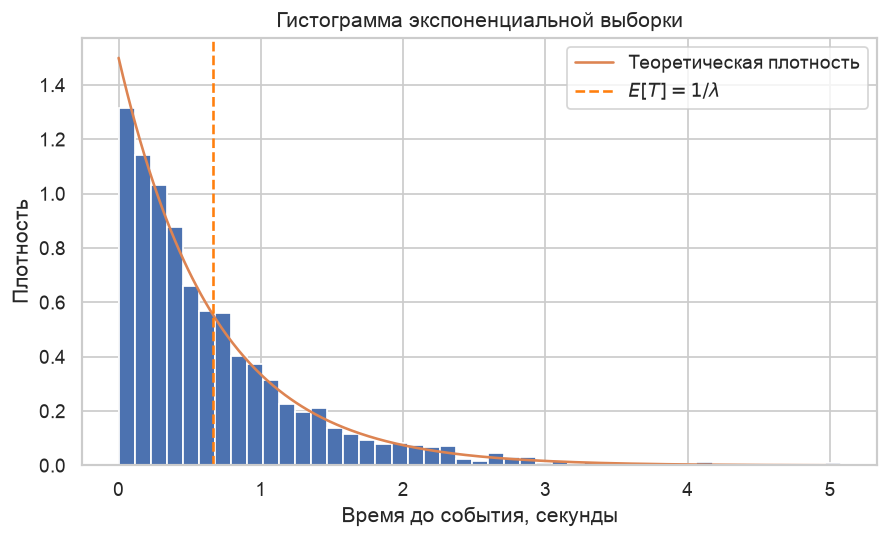

In [4]:
rng = np.random.default_rng(42)
lambda_ = 1.5
distribution = stats.expon(scale=1 / lambda_)
sample = distribution.rvs(size=2000, random_state=rng)

fig, ax = plt.subplots(figsize=(7, 4.2), layout="constrained")
ax.hist(sample, bins="auto", density=True, edgecolor="white")
x_exp = np.linspace(0, sample.max(), 501)
ax.plot(x_exp, distribution.pdf(x_exp), label="Теоретическая плотность")
ax.axvline(1 / lambda_, color="tab:orange", linestyle="--", label=r"$E[T]=1/\lambda$")
ax.set(
    xlabel="Время до события, секунды",
    ylabel="Плотность",
    title="Гистограмма экспоненциальной выборки",
)
ax.legend()
plt.show()

## 3.3. Вероятности биномиального распределения

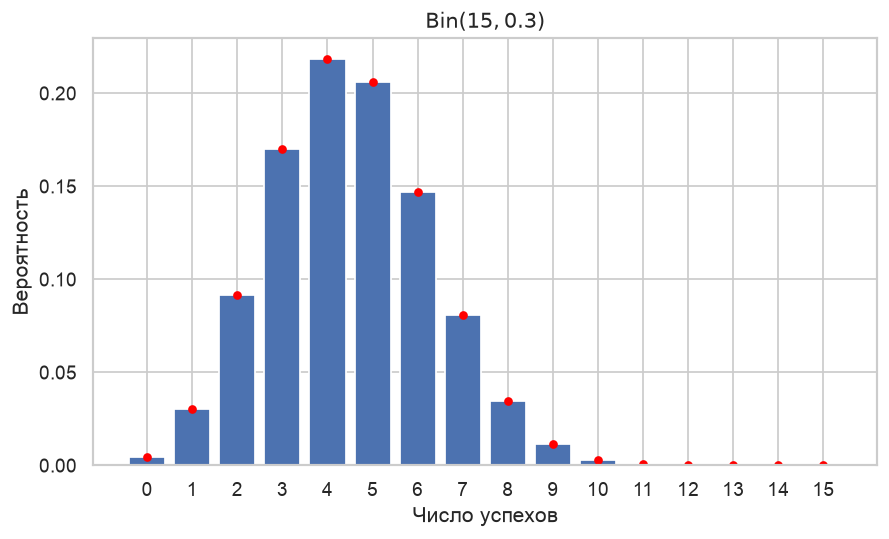

In [5]:
k = np.arange(16)
probabilities = stats.binom.pmf(k, n=15, p=0.3)
assert np.isclose(probabilities.sum(), 1), "Сумма вероятностей должна быть равна 1"

fig, ax = plt.subplots(figsize=(7, 4.2), layout="constrained")
plt.bar(k, probabilities)
plt.plot(k, probabilities, "o", color="red", markersize=4)
ax.set(xlabel="Число успехов", ylabel="Вероятность", title=r"$\mathrm{Bin}(15, 0.3)$", xticks=k)
plt.show()

## 3.4. Круговая диаграмма

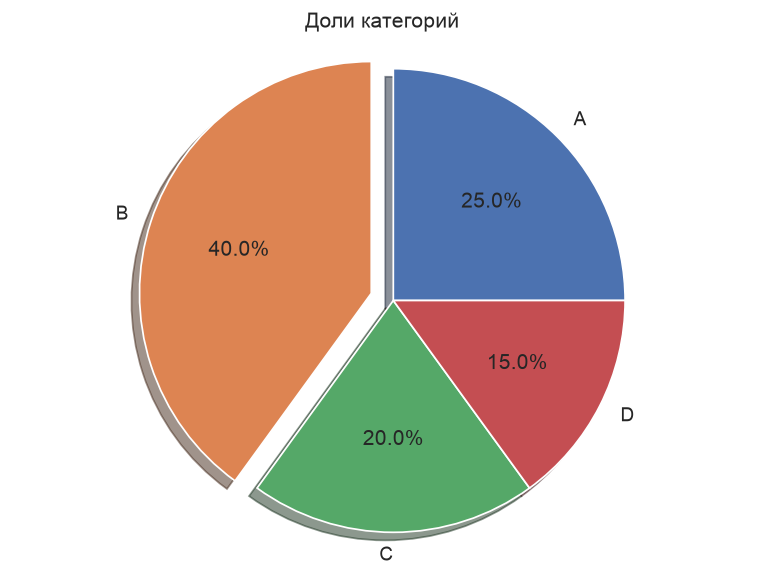

In [6]:
data = pd.DataFrame({
    "category": ["A", "B", "C", "D"],
    "share": [25, 40, 20, 15],
})

fig, ax = plt.subplots(figsize=(6, 4.5), layout="constrained")
plt.pie(
    data["share"],
    labels=data["category"],
    autopct="%.1f%%",
    shadow=True,
    explode=[0, 0.1, 0, 0],
)
plt.axis("equal")
ax.set_title("Доли категорий")
plt.show()

## 3.5. Точки и линейная регрессия

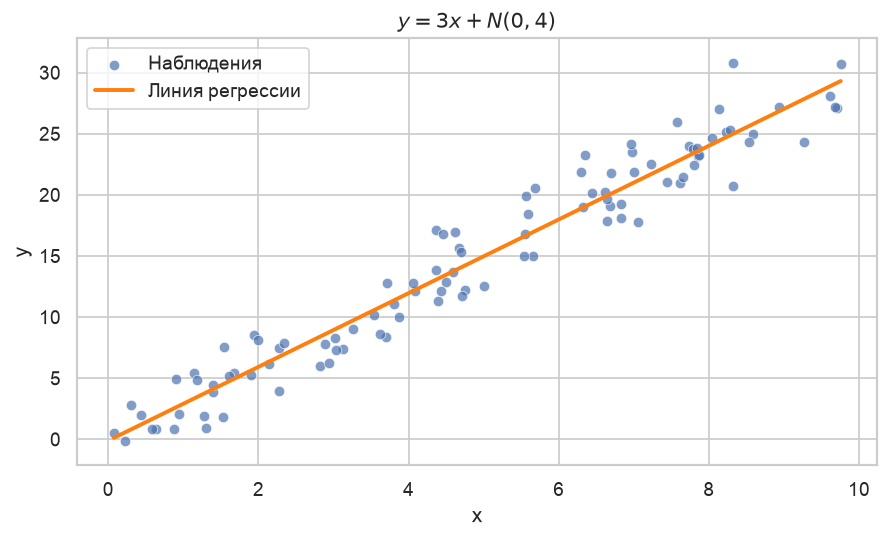

In [7]:
rng = np.random.default_rng(42)
x = rng.uniform(0, 10, size=100)
noise = rng.normal(0, 2, size=100)
y = 3 * x + noise

fig, ax = plt.subplots(figsize=(7, 4.2), layout="constrained")
sns.scatterplot(x=x, y=y, alpha=0.7, ax=ax, label="Наблюдения")
sns.regplot(x=x, y=y, scatter=False, ci=None, ax=ax, color="tab:orange", label="Линия регрессии")
ax.set(
    xlabel="x",
    ylabel="y",
    title=r"$y=3x+N(0,4)$",
    ylim=(y.min() - 2, y.max() + 2),
)
ax.legend()
plt.show()

## Уроки 4 и 5. Выбор распределения

- **4.1. Гипергеометрическое.** Из партии из 100 деталей с 12 дефектными выбирают 10 деталей без возвращения. Случайная величина считает дефектные детали в выборке.
- **5.1. Экспоненциальное.** При пуассоновском потоке с интенсивностью 4 запроса в минуту время до следующего запроса имеет параметр λ = 4 и среднее 1/4 минуты.